In [2]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
import numpy as np, pandas as pd, random, warnings
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso, SGDRegressor
from sklearn.metrics import mean_squared_error, r2_score

SEED = 0
random.seed(SEED); np.random.seed(SEED)

DATA_DIR = "/content/drive/MyDrive"   # CSVs directly in My Drive (no folder). Elsewhere: use "."
TARGET = "rentals"
WEATHER = ["temperature", "precipitation", "humidity", "wind_speed"]

train_all = pd.read_csv(f"{DATA_DIR}/train.csv", parse_dates=["datetime"])
test_df   = pd.read_csv(f"{DATA_DIR}/test.csv",  parse_dates=["datetime"])
VAL_START = pd.Timestamp("2026-05-01")
tr_raw = train_all[train_all["datetime"] <  VAL_START]
va_raw = train_all[train_all["datetime"] >= VAL_START]

def add_features(df):
    d = df.copy()
    dt = d["datetime"]
    d["hour"] = dt.dt.hour
    d["dow"] = dt.dt.dayofweek
    d["is_weekend"] = (d["dow"] >= 5).astype(int)
    d["is_offday"] = ((d["is_weekend"] == 1) | (d["is_holiday"] == 1)).astype(int)
    for k in (1, 2):
        d[f"hour_sin{k}"] = np.sin(2 * np.pi * k * d["hour"] / 24)
        d[f"hour_cos{k}"] = np.cos(2 * np.pi * k * d["hour"] / 24)
    d["peak"] = np.select([d["hour"].between(7, 9), d["hour"].between(17, 19)], ["am", "pm"], "off")
    d["station"] = d["station"].astype(str)
    d["district"] = d["district"].astype(str)
    d["daytype_hour"] = d["is_offday"].astype(str) + "_" + d["hour"].astype(str)          # hour profile per day type
    d["station_peak"] = d["station"] + "_" + d["peak"] + "_" + d["is_offday"].astype(str)  # commute direction per station
    d["rain_flag"] = (d["precipitation"] > 0).astype(int)
    d["precip_peak"] = d["precipitation"] * (d["peak"] != "off")
    d["temp_sq"] = d["temperature"] ** 2
    return d

tr, va, te = add_features(tr_raw), add_features(va_raw), add_features(test_df)

S1_num = WEATHER + ["is_holiday"]
S1_cat = ["hour", "dow"]
S2_num = S1_num + ["capacity"]
S2_cat = S1_cat + ["station", "district"]
S3_num = S2_num + ["rain_flag", "precip_peak", "temp_sq"]
S3_cat = S2_cat + ["daytype_hour", "station_peak"]
FS = {
    "S0 baseline (weather)": (WEATHER, []),
    "S1 + time (hour, weekday, holiday)": (S1_num, S1_cat),
    "S2 + station (id, district, capacity)": (S2_num, S2_cat),
    "S3 + interactions (rain, day-type x hour, station x peak)": (S3_num, S3_cat),
}

USE_LOG = True

def safe_expm1(z):
    return np.expm1(np.clip(z, -5, 8))

def wrap(pipe, log=None):
    log = USE_LOG if log is None else log
    if log:
        return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=safe_expm1)
    return TransformedTargetRegressor(regressor=pipe, func=None, inverse_func=None)

def make_pipe(num, cat, model, scaler="standard"):
    sc = {"standard": StandardScaler(), "minmax": MinMaxScaler(), "none": "passthrough"}[scaler]
    tf = [("num", sc, num)]
    if cat:
        tf.append(("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat))
    return Pipeline([("prep", ColumnTransformer(tf)), ("model", model)])

def rmse(y, p): return float(np.sqrt(mean_squared_error(y, p)))

def fit_eval(pipe, num, cat, data_tr=None, data_va=None, log=None):
    data_tr = tr if data_tr is None else data_tr
    data_va = va if data_va is None else data_va
    cols = num + cat
    m = wrap(pipe, log).fit(data_tr[cols], data_tr[TARGET])
    ptr = np.clip(m.predict(data_tr[cols]), 0, None)     # negative predictions are clipped to 0
    pva = np.clip(m.predict(data_va[cols]), 0, None)
    n_feat = m.regressor_.named_steps["prep"].get_feature_names_out().shape[0]
    return m, dict(n_features=n_feat,
                   train_RMSE=rmse(data_tr[TARGET], ptr),
                   val_RMSE=rmse(data_va[TARGET], pva),
                   val_R2=float(r2_score(data_va[TARGET], pva)))

print(tr.shape, va.shape, te.shape)
tr[["datetime", "station", TARGET, "hour", "dow", "is_offday", "peak"]].head()

(86400, 25) (22320, 25) (21600, 24)


,datetime,station,rentals,hour,dow,is_offday,peak
0,2026-01-01,中華桂林路口,2,0,3,1,off
1,2026-01-01,大稻埕碼頭,14,0,3,1,off
2,2026-01-01,捷運中山國中站,23,0,3,1,off
3,2026-01-01,捷運信義安和站(4號出口),0,0,3,1,off
4,2026-01-01,捷運公館站(2號出口),18,0,3,1,off


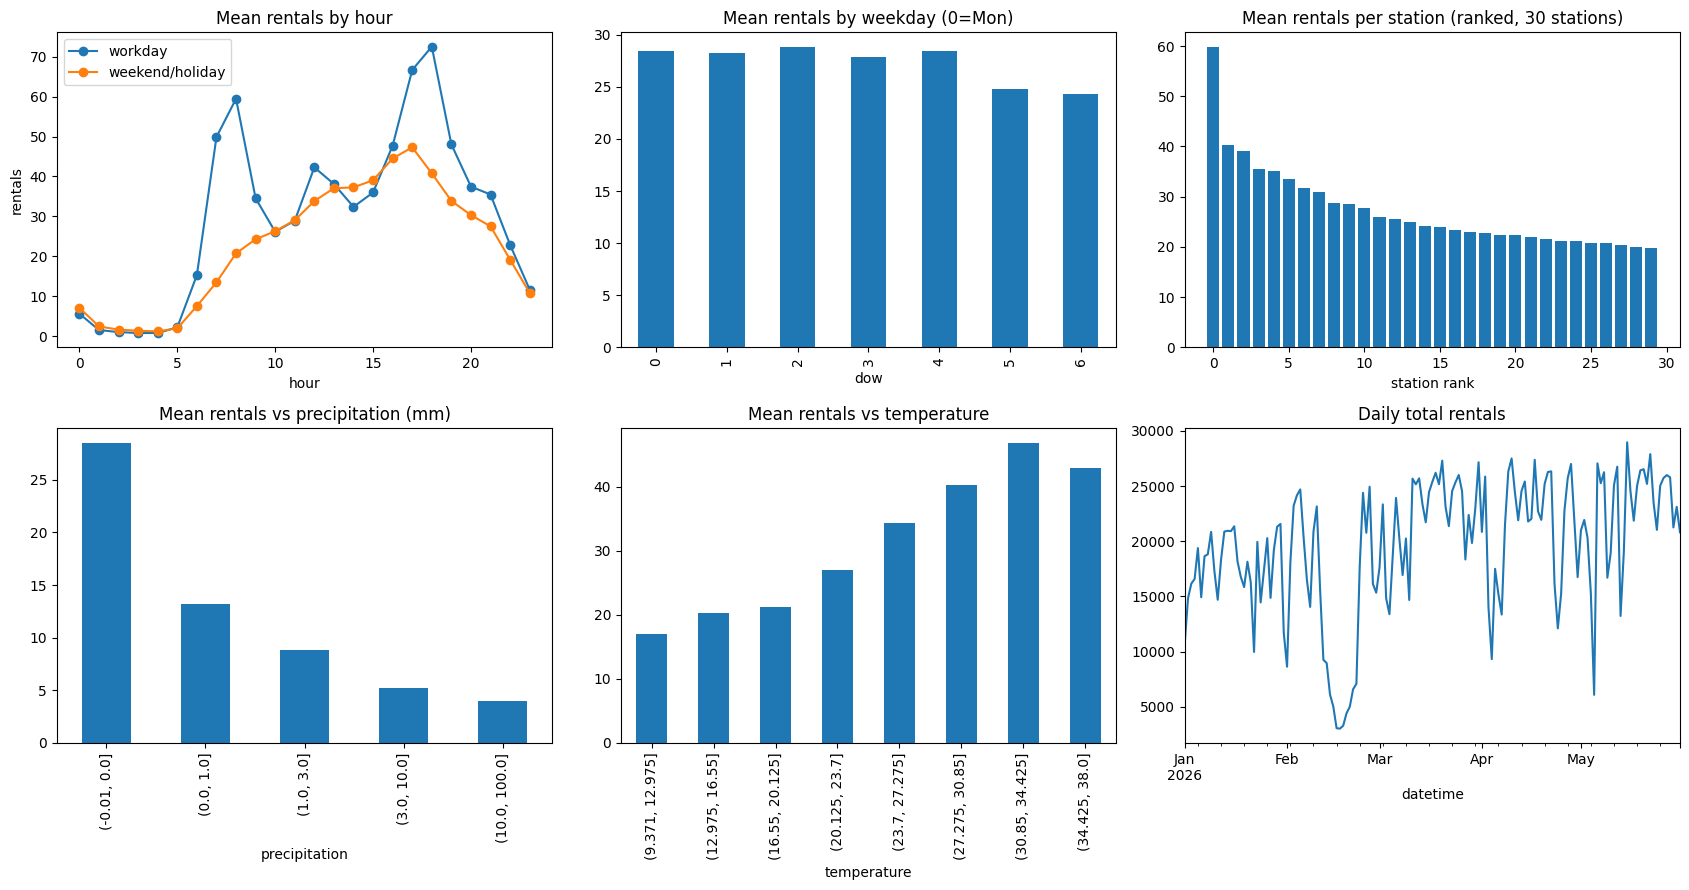

Target: mean 27.24, std 28.03, max 257, share of zeros 9.8%, skew 1.69
station
捷運公館站(2號出口)    59.7
捷運科技大樓站        40.4
捷運圓山站(1號出口)    39.1
捷運東門站(5號出口)    35.4
捷運中山國中站        35.0
Name: rentals, dtype: float64 
...
 station
臺灣科技大學後門           20.4
捷運大安森林公園站(5號出口)    20.0
捷運北投站(1號出口)        19.9
Name: rentals, dtype: float64


peak,am,off,pm,pm/am
station,,,,
捷運芝山站(1號出口),63.467354,14.705040,47.068729,0.741621
捷運台北101/世貿站(2號出口),58.646048,14.347079,44.103093,0.752022
捷運六張犁站,78.560137,21.032646,59.639175,0.759153
大稻埕碼頭,12.295533,16.554983,44.443299,3.614589
松仁路95巷口,9.666667,18.179267,85.388316,8.833274
臺大第一活動中心西南側,7.295533,28.272050,76.958763,10.548752


In [4]:
fig, ax = plt.subplots(2, 3, figsize=(17, 9))
d = pd.concat([tr, va])

for k, lab in [(0, "workday"), (1, "weekend/holiday")]:
    ax[0, 0].plot(d[d.is_offday == k].groupby("hour")[TARGET].mean(), marker="o", label=lab)
ax[0, 0].set(title="Mean rentals by hour", xlabel="hour", ylabel="rentals"); ax[0, 0].legend()

d.groupby("dow")[TARGET].mean().plot.bar(ax=ax[0, 1], title="Mean rentals by weekday (0=Mon)")

st_mean = d.groupby("station")[TARGET].mean().sort_values(ascending=False)
ax[0, 2].bar(range(len(st_mean)), st_mean.values); ax[0, 2].set(title="Mean rentals per station (ranked, 30 stations)", xlabel="station rank")

pb = pd.cut(d["precipitation"], [-0.01, 0, 1, 3, 10, 100])
d.groupby(pb, observed=True)[TARGET].mean().plot.bar(ax=ax[1, 0], title="Mean rentals vs precipitation (mm)")

tb = pd.cut(d["temperature"], 8)
d.groupby(tb, observed=True)[TARGET].mean().plot.bar(ax=ax[1, 1], title="Mean rentals vs temperature")

d.set_index("datetime")[TARGET].resample("D").sum().plot(ax=ax[1, 2], title="Daily total rentals")
plt.tight_layout(); plt.show()

print("Target: mean %.2f, std %.2f, max %d, share of zeros %.1f%%, skew %.2f" % (
    d[TARGET].mean(), d[TARGET].std(), d[TARGET].max(), 100 * (d[TARGET] == 0).mean(), d[TARGET].skew()))
print(st_mean.round(1).head(5), "\n...\n", st_mean.round(1).tail(3))
prof = d[d.is_offday == 0].groupby(["station", "peak"])[TARGET].mean().unstack()
prof["pm/am"] = prof["pm"] / prof["am"]
prof.sort_values("pm/am").iloc[[0, 1, 2, -3, -2, -1]]

In [5]:
m0 = LinearRegression().fit(tr[WEATHER], tr[TARGET])
for name, d_ in [("train", tr), ("val", va)]:
    p = m0.predict(d_[WEATHER])
    print(name, "RMSE %.3f  R2 %.3f" % (rmse(d_[TARGET], p), r2_score(d_[TARGET], p)))

train RMSE 25.095  R2 0.144
val RMSE 29.388  R2 0.098


,target,train_RMSE,val_RMSE,val_R2
0,y (raw),25.089344,29.374503,0.098804
1,log1p(y),28.461579,38.158507,-0.520761


,target,train_RMSE,val_RMSE,val_R2
0,y (raw),14.634195,16.669620,0.709778
1,log1p(y),14.663444,16.018221,0.732017


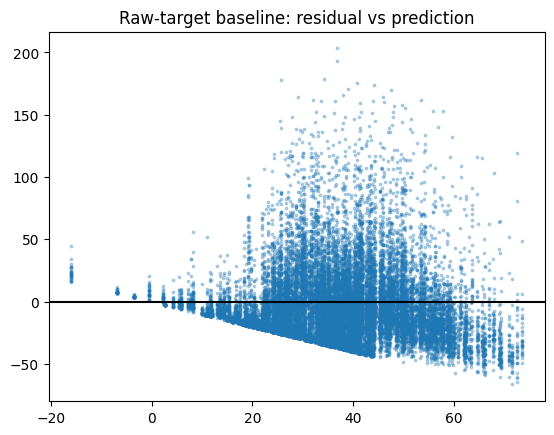

In [6]:
# Baseline:
rows = []
for flag in (False, True):
    USE_LOG = flag
    _, r = fit_eval(make_pipe(WEATHER, [], LinearRegression()), WEATHER, [])
    rows.append(dict(target="log1p(y)" if flag else "y (raw)", **r))
base_table = pd.DataFrame(rows).drop(columns="n_features"); display(base_table)

rows = []
for flag in (False, True):
    USE_LOG = flag
    n, c = FS["S3 + interactions (rain, day-type x hour, station x peak)"]
    _, r = fit_eval(make_pipe(n, c, Ridge(alpha=10)), n, c)
    rows.append(dict(target="log1p(y)" if flag else "y (raw)", **r))
display(pd.DataFrame(rows).drop(columns="n_features"))

USE_LOG = False
m, _ = fit_eval(make_pipe(WEATHER, [], LinearRegression()), WEATHER, [])
p = m.predict(va[WEATHER]); res_ = va[TARGET] - p
plt.scatter(p, res_, s=3, alpha=.3); plt.axhline(0, c="k"); plt.title("Raw-target baseline: residual vs prediction"); plt.show()

In [7]:
USE_LOG = True
enc = {
 "raw hour (numeric)":       (WEATHER + ["hour"], []),
 "hour sin/cos (k=1,2)":     (WEATHER + ["hour_sin1", "hour_cos1", "hour_sin2", "hour_cos2"], []),
 "hour one-hot":             (WEATHER, ["hour"]),
 "hour one-hot x day-type":  (WEATHER, ["daytype_hour"]),
}
rows = []
for k, (n, c) in enc.items():
    _, r = fit_eval(make_pipe(n, c, Ridge(alpha=10)), n, c)
    rows.append(dict(encoding=k, **r))
pd.DataFrame(rows)

,encoding,n_features,train_RMSE,val_RMSE,val_R2
0,raw hour (numeric),5,26.181477,31.888999,-0.062087
1,"hour sin/cos (k=1,2)",8,22.095715,24.098300,0.393472
2,hour one-hot,28,20.838978,22.679220,0.462802
3,hour one-hot x day-type,52,19.370376,21.793215,0.503955


In [8]:
ALPHA = 10
rows = []; models = {}
for name, (n, c) in FS.items():
    m, r = fit_eval(make_pipe(n, c, Ridge(alpha=ALPHA)), n, c)
    models[name] = m; rows.append(dict(feature_set=name, **r))
fs_table = pd.DataFrame(rows)
fs_table["delta_val_RMSE"] = fs_table["val_RMSE"].diff()
fs_table

,feature_set,n_features,train_RMSE,val_RMSE,val_R2,delta_val_RMSE
0,S0 baseline (weather),4,28.461153,38.153265,-0.520344,NaN
1,"S1 + time (hour, weekday, holiday)",36,20.099660,22.371978,0.477258,-15.781287
2,"S2 + station (id, district, capacity)",76,18.032188,19.893074,0.586684,-2.478904
3,"S3 + interactions (rain, day-type x hour, stat...",307,14.663444,16.018221,0.732017,-3.874854


In [9]:
m = models[list(FS)[-1]]
names = m.regressor_.named_steps["prep"].get_feature_names_out()
coef = pd.Series(m.regressor_.named_steps["model"].coef_, index=names)
print(coef.reindex(coef.abs().sort_values(ascending=False).index).head(15))

cat__hour_3                          -1.327050
cat__hour_4                          -1.304509
cat__hour_2                          -1.256640
cat__hour_1                          -1.145537
cat__hour_5                          -1.075269
cat__station_peak_松仁路95巷口_am_0       -1.038179
cat__station_peak_大稻埕碼頭_am_0         -1.026545
cat__station_peak_臺大第一活動中心西南側_am_0   -0.931083
cat__daytype_hour_0_3                -0.891053
cat__daytype_hour_0_2                -0.865400
cat__daytype_hour_0_4                -0.853788
cat__daytype_hour_0_1                -0.823828
cat__station_peak_臺大第一活動中心西南側_pm_0    0.792408
cat__station_peak_大稻埕碼頭_pm_1          0.782480
cat__hour_17                          0.757582
dtype: float64


In [10]:
S3_name = list(FS)[-1]; n3, c3 = FS[S3_name]
warnings.filterwarnings("ignore")

def sgd(eta0): return SGDRegressor(penalty=None, learning_rate="constant", eta0=eta0, max_iter=1000,
                                   tol=1e-4, n_iter_no_change=5, random_state=SEED)
zoo = {
    "OLS (closed form)":     lambda: LinearRegression(),
    "Ridge a=100 (closed)":  lambda: Ridge(alpha=100),
    "SGD eta0=1e-3":         lambda: sgd(1e-3),
    "SGD eta0=1e-5":         lambda: sgd(1e-5),
    "SGD eta0=1e-7":         lambda: sgd(1e-7),
}
rows = []
for sc in ["none", "standard", "minmax"]:
    for mname, mk in zoo.items():
        try:
            m, r = fit_eval(make_pipe(n3, c3, mk(), scaler=sc), n3, c3)
            it = getattr(m.regressor_.named_steps["model"], "n_iter_", None)
            it = int(it) if it is not None else "-"
            w = getattr(m.regressor_.named_steps["model"], "coef_", np.zeros(1))
            if (not np.all(np.isfinite(w))) or np.abs(w).max() > 1e4:      # exploded weights
                status = "diverged"
            else:
                status = "hit max_iter" if it == 1000 else "ok"
            val = r["val_RMSE"] if status != "diverged" else np.nan
        except Exception as e:
            val, it, status = np.nan, "-", "diverged"
        rows.append(dict(scaling=sc, model=mname, val_RMSE=val, n_iter=it, status=status))
scale_table = pd.DataFrame(rows)
display(scale_table.pivot(index="model", columns="scaling", values="val_RMSE")[["none", "standard", "minmax"]])
display(scale_table)

scaling,none,standard,minmax
model,,,
OLS (closed form),15.956038,15.956038,15.956038
Ridge a=100 (closed),16.522746,16.550127,16.891904
SGD eta0=1e-3,NaN,16.286527,16.405048
SGD eta0=1e-5,NaN,17.741329,18.140373
SGD eta0=1e-7,23.345780,29.580016,25.134194


,scaling,model,val_RMSE,n_iter,status
0,none,OLS (closed form),15.956038,-,ok
1,none,Ridge a=100 (closed),16.522746,-,ok
2,none,SGD eta0=1e-3,NaN,8,diverged
3,none,SGD eta0=1e-5,NaN,8,diverged
4,none,SGD eta0=1e-7,23.345780,1000,hit max_iter
5,standard,OLS (closed form),15.956038,-,ok
6,standard,Ridge a=100 (closed),16.550127,-,ok
7,standard,SGD eta0=1e-3,16.286527,16,ok
8,standard,SGD eta0=1e-5,17.741329,106,ok
9,standard,SGD eta0=1e-7,29.580016,1000,hit max_iter
